In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [ ]:
data = {
    'Age': ['Young', 'Young', 'Middle', 'Senior', 'Senior', 'Middle', 'Senior',
            'Youth', 'Youth', 'Senior', 'Youth', 'Middle', 'Middle', 'Senior'],
    'Income': ['High', 'High', 'High', 'Medium', 'Low', 'Low', 'Low', 'Medium',
               'Low', 'Medium', 'Medium', 'Medium', 'High', 'Medium'],
    'Student': ['No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes',
                'Yes', 'No', 'Yes', 'No'],
    'Credit_rating': ['Fair', 'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent',
                      'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent',
                      'Fair', 'Excellent'],
    'Buys_computer': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes',
                      'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

In [ ]:
df = pd.DataFrame(data)

In [ ]:
df

,Age,Income,Student,Credit_rating,Buys_computer
0,Young,High,No,Fair,No
1,Young,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes
5,Middle,Low,Yes,Excellent,No
6,Senior,Low,Yes,Excellent,Yes
7,Youth,Medium,No,Fair,No
8,Youth,Low,Yes,Fair,Yes
9,Senior,Medium,Yes,Fair,Yes


In [ ]:
le = {}
df_enc = df.copy()
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

In [ ]:
df_enc

,Age,Income,Student,Credit_rating,Buys_computer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,1,1,0,1
7,3,2,0,1,0
8,3,1,1,1,1
9,1,2,1,1,1


In [ ]:
X = df_enc[['Age', 'Income', 'Student', 'Credit_rating']]
y = df_enc['Buys_computer']

In [ ]:
X

,Age,Income,Student,Credit_rating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,1,1,0
7,3,2,0,1
8,3,1,1,1
9,1,2,1,1


In [ ]:
y

,Buys_computer
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [ ]:
model = CategoricalNB()
model.fit(X, y)

CategoricalNB()

In [ ]:
test = [['Youth', 'Medium', 'Yes', 'Fair']]

In [ ]:
test

[['Youth', 'Medium', 'Yes', 'Fair']]

In [ ]:
print("\n-- Prediction-------------------------------------------------------------")
for  t in test:
  row = [[
      le['Age'].transform([t[0]])[0],
      le['Income'].transform([t[1]])[0],
      le['Student'].transform([t[2]])[0],
      le['Credit_rating'].transform([t[3]])[0]
  ]]
  pred = le['Buys_computer'].inverse_transform(model.predict(row))[0]
  prob = model.predict_proba(row)[0]
  print(f"Input : Age={t[0]}, Income={t[1]}, Student={t[2]}, CreditRating={t[3]}")
  print(f"Result: Buys Computer -> {pred}")
  print(f"P(No) = {prob[0]:.4f}")
  print(f"P(Yes) = {prob[1]:.4f}")
  print("--------------------------------------------------------------------------")


-- Prediction-------------------------------------------------------------
Input : Age=Youth, Income=Medium, Student=Yes, CreditRating=Fair
Result: Buys Computer -> Yes
P(No) = 0.1271
P(Yes) = 0.8729
--------------------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X)
print(f"\nTraining Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 71.43%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


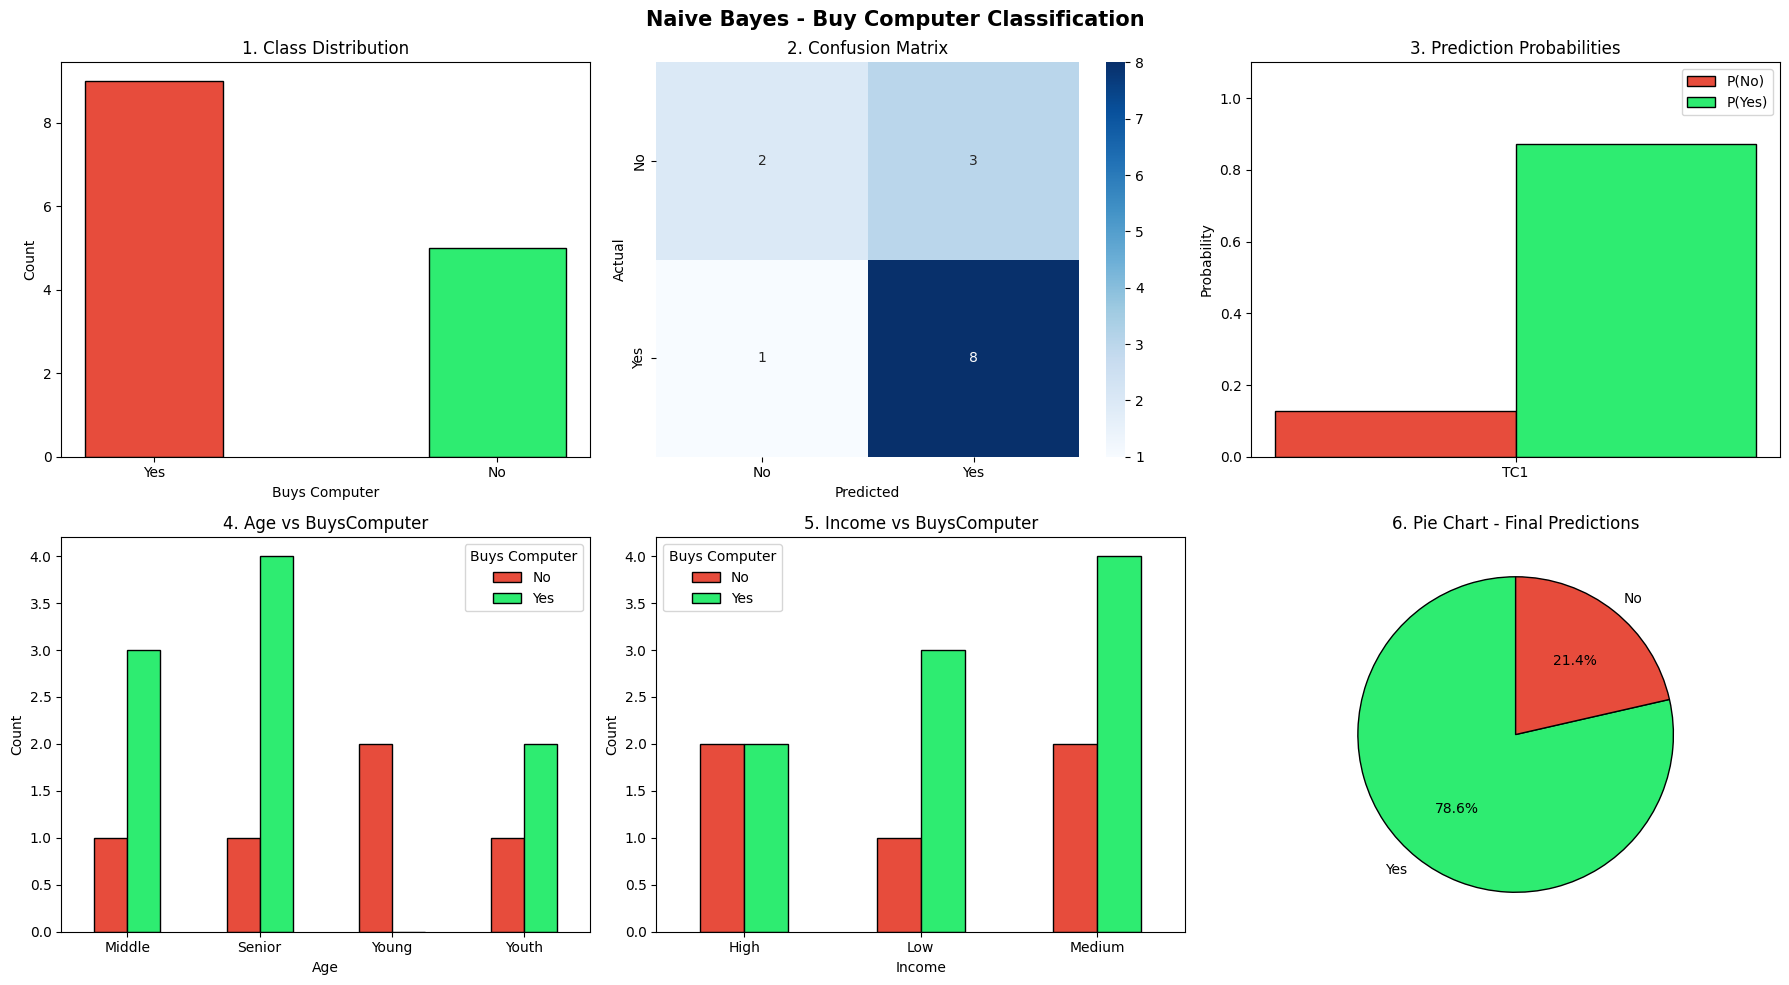

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# ---Plots--------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Naive Bayes - Buy Computer Classification", fontsize=15, fontweight='bold')

# 1. Class Distribution
counts = df['Buys_computer'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#e74c3c','#2eec71'], edgecolor='black', width=0.4)
axes[0, 0].set_title('1. Class Distribution')
axes[0, 0].set_xlabel('Buys Computer')
axes[0, 0].set_ylabel('Count')

# 2. Confusion Matrix
y_pred = model.predict(X)
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'], ax=axes[0,1])
axes[0, 1].set_title('2. Confusion Matrix')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Actual')

# 3. Prediction Probabilities (Grouped Bar)
# Extracting probabilities for the provided test cases
test_cases = [f"TC{i+1}" for i in range(len(test))]
prob_no = []
prob_yes = []
for t in test:
    row = [[
        le['Age'].transform([t[0]])[0],
        le['Income'].transform([t[1]])[0],
        le['Student'].transform([t[2]])[0],
        le['Credit_rating'].transform([t[3]])[0]
    ]]
    p = model.predict_proba(row)[0]
    prob_no.append(p[0])
    prob_yes.append(p[1])

x = np.arange(len(test_cases))
width = 0.3
axes[0,2].bar(x - width/2, prob_no, width, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0,2].bar(x + width/2, prob_yes, width, label='P(Yes)', color='#2eec71', edgecolor='black')
axes[0,2].set_title('3. Prediction Probabilities')
axes[0,2].set_xticks(x)
axes[0,2].set_xticklabels(test_cases)
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

# 4. Age vs BuysComputer
age_counts = df.groupby(['Age', 'Buys_computer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1,0], color=['#e74c3c','#2eec71'], edgecolor='black', rot=0)
axes[1,0].set_title("4. Age vs BuysComputer")
axes[1,0].set_xlabel("Age")
axes[1,0].set_ylabel("Count")
axes[1,0].legend(title="Buys Computer")

# 5. Income vs BuysComputer
inc_counts = df.groupby(['Income', 'Buys_computer']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', ax=axes[1,1], color=['#e74c3c','#2eec71'], edgecolor='black', rot=0)
axes[1,1].set_title("5. Income vs BuysComputer")
axes[1,1].set_xlabel("Income")
axes[1,1].set_ylabel("Count")
axes[1,1].legend(title="Buys Computer")

# 6. Pie Chart - Final Predictions
predictions = le['Buys_computer'].inverse_transform(y_pred)
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2eec71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1,2].pie(pred_counts.values, labels=pred_counts.index, autopct='%1.1f%%',
              colors=colors_pie, startangle=90,
              wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6. Pie Chart - Final Predictions")

plt.tight_layout()
plt.show()